**1. install and import libraries**

In [1]:
# install Libraries ( for collab)
!pip install nltk seaborn
!pip install contractions


# import Libraries
print("Importing libraries...")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import re
import nltk
import contractions
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, precision_recall_curve

print("All libraries imported successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.9/289.9 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.3/118.3 kB 10.8 MB/s eta 0:00:00
Importing libraries...
All libraries imported successfully!


**2. load dataset**

In [2]:
print("Loading dataset...")

# upload and load your file
from google.colab import files
uploaded = files.upload()

data = pd.read_csv(next(iter(uploaded)))
print("Dataset loaded successfully!")
data.head()

Loading dataset...


Saving spam_detection_training_data.csv to spam_detection_training_data.csv
Dataset loaded successfully!


,text,label
0,Subject: re : tenaska\r\ni see the demand fee ...,0
1,Subject: strong buy alert : monthly newsletter...,1
2,Subject: performance feedback\r\neach of you h...,0
3,Subject: hr performance objectives binders\r\n...,0
4,Subject: fw : [ fwd : fw : drawing by a school...,0


**3. initial data exploration**

In [3]:
print("Dataset info:")
print(data.info())

print("\nChecking for missing values:")
print(data.isnull().sum())

print("\nDataset sample:")
print(data.sample(5))

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3619 entries, 0 to 3618
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    3619 non-null   object
 1   label   3619 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 56.7+ KB
None

Checking for missing values:
text     0
label    0
dtype: int64

Dataset sample:
                                                   text  label
2238  Subject: re : october wellhead\r\nthe heatherl...      0
2493  Subject: anomaly boys from 3881\r\nuosda apapr...      1
1460  Subject: enron / hpl actuals for 10 / 19 / 00\...      0
2269  Subject: welcome to woodworkingtips . com !\r\...      0
2827  Subject: small - cap market advisors\r\nhidden...      1


**4. text preprocessing**

In [4]:
print("Starting text preprocessing...")

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # expand contractions
    text = contractions.fix(text)
    # lowercase
    text = text.lower()
    # remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # remove numbers
    text = re.sub(r'\d+', '', text)
    # split into words
    words = text.split()
    # Remove stopwords
    words = [w for w in words if w not in stop_words]
    # stemming and lemmatization
    words = [stemmer.stem(w) for w in words]
    words = [lemmatizer.lemmatize(w) for w in words]
    # put the words back together
    return ' '.join(words)

#  cleaning
data['clean_text'] = data['text'].apply(clean_text)

print("\nPreprocessing complete. Sample after cleaning:")
data[['text', 'clean_text']].head()

Starting text preprocessing...


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...



Preprocessing complete. Sample after cleaning:


,text,clean_text
0,Subject: re : tenaska\r\ni see the demand fee ...,subject tenaska see demand fee chang william p...
1,Subject: strong buy alert : monthly newsletter...,subject strong buy alert monthli newslett tops...
2,Subject: performance feedback\r\neach of you h...,subject perform feedback chosen one direct rep...
3,Subject: hr performance objectives binders\r\n...,subject hr perform object binder good morn aft...
4,Subject: fw : [ fwd : fw : drawing by a school...,subject fw fwd fw draw school age child pa fwd...


**5. feature extraction**

In [5]:
print("Extracting features...")

# Bag of Words (BoW)
bow_vectorizer = CountVectorizer()
X_bow = bow_vectorizer.fit_transform(data['clean_text'])

# TF-IDF
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(data['clean_text'])

# Labels
y = data['label']

print(f"BoW feature shape: {X_bow.shape}")
print(f"TF-IDF feature shape: {X_tfidf.shape}")


Extracting features...
BoW feature shape: (3619, 30770)
TF-IDF feature shape: (3619, 30770)


**6. train-test split**

In [6]:
print("Splitting dataset...")

#splitting BoW features into train and validation sets (80% train, 20% test)
X_train_bow, X_val_bow, y_train, y_val = train_test_split(X_bow, y, test_size=0.2, random_state=42)

# doing the same for TF-IDF features
X_train_tfidf, X_val_tfidf, _, _ = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

print("Split complete.")

Splitting dataset...
Split complete.


**7. model training**

In [7]:
# training Naive Bayes using BoW
print("Training Multinomial Naive Bayes with BoW...")
nb_bow = MultinomialNB()
nb_bow.fit(X_train_bow, y_train)

# training Logistic Regression on TF-IDF features
print("Training Logistic Regression with TF-IDF...")
lr_tfidf = LogisticRegression(max_iter=1000)
lr_tfidf.fit(X_train_tfidf, y_train)

# training SVM on TF-IDF features
print("Training SVM with TF-IDF...")
svm_tfidf = SVC(probability=True)
svm_tfidf.fit(X_train_tfidf, y_train)

print("All models trained successfully!")


Training Multinomial Naive Bayes with BoW...
Training Logistic Regression with TF-IDF...
Training SVM with TF-IDF...
All models trained successfully!


**8. model evaluation**

In [8]:
print("Evaluating Models...\n")

# Naive Bayes Evaluation
nb_preds = nb_bow.predict(X_val_bow)
print("NB BoW Classification Report:\n", classification_report(y_val, nb_preds))

# Logistic Regression Evaluation
lr_preds = lr_tfidf.predict(X_val_tfidf)
print("Logistic Regression TF-IDF Classification Report:\n", classification_report(y_val, lr_preds))

# SVM Evaluation
svm_preds = svm_tfidf.predict(X_val_tfidf)
print("SVM TF-IDF Classification Report:\n", classification_report(y_val, svm_preds))

Evaluating Models...

NB BoW Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98       509
           1       0.95      0.95      0.95       215

    accuracy                           0.97       724
   macro avg       0.96      0.97      0.97       724
weighted avg       0.97      0.97      0.97       724

Logistic Regression TF-IDF Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99       509
           1       0.95      0.99      0.97       215

    accuracy                           0.98       724
   macro avg       0.97      0.98      0.98       724
weighted avg       0.98      0.98      0.98       724

SVM TF-IDF Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99       509
           1       0.96      0.99      0.97       215

    accuracy                           0.98

**9. plotting confusion matrices**

Plotting confusion matrices...


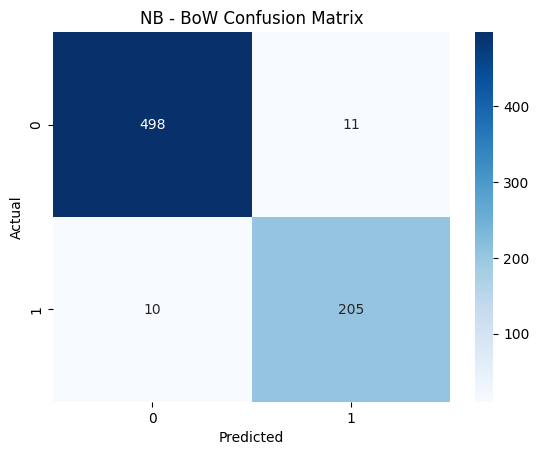

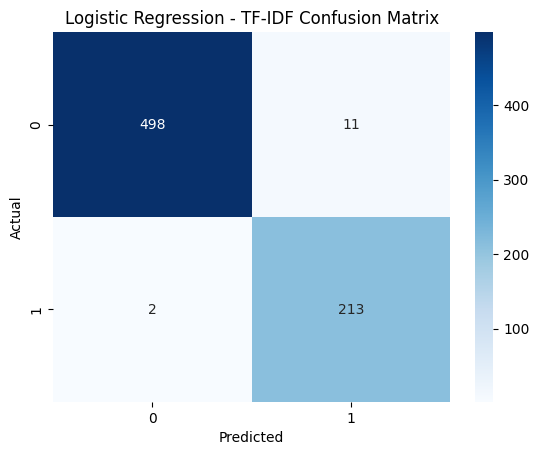

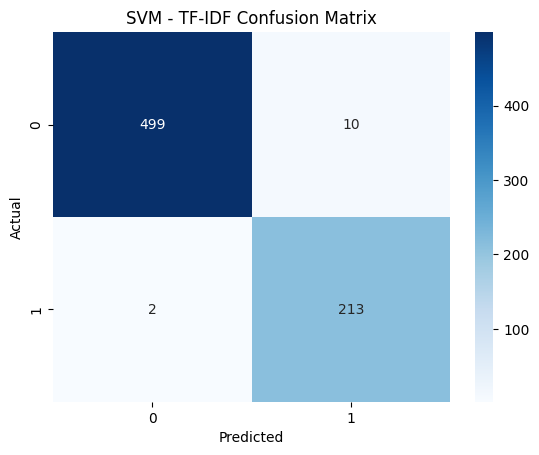

In [9]:
print("Plotting confusion matrices...")

def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# plotting confusion matrix for each model
plot_cm(y_val, nb_preds, "NB - BoW Confusion Matrix")
plot_cm(y_val, lr_preds, "Logistic Regression - TF-IDF Confusion Matrix")
plot_cm(y_val, svm_preds, "SVM - TF-IDF Confusion Matrix")

**10. ROC curve and precision-recall curve**

Plotting ROC and PR curves...


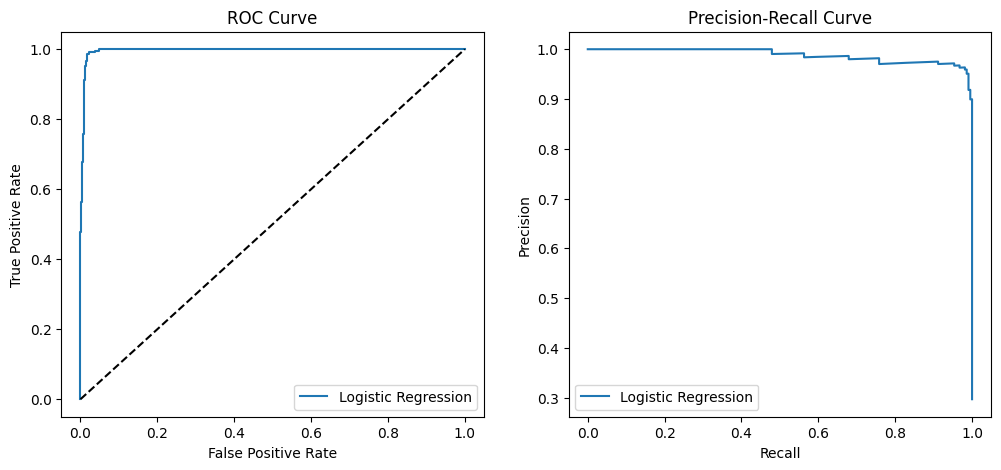

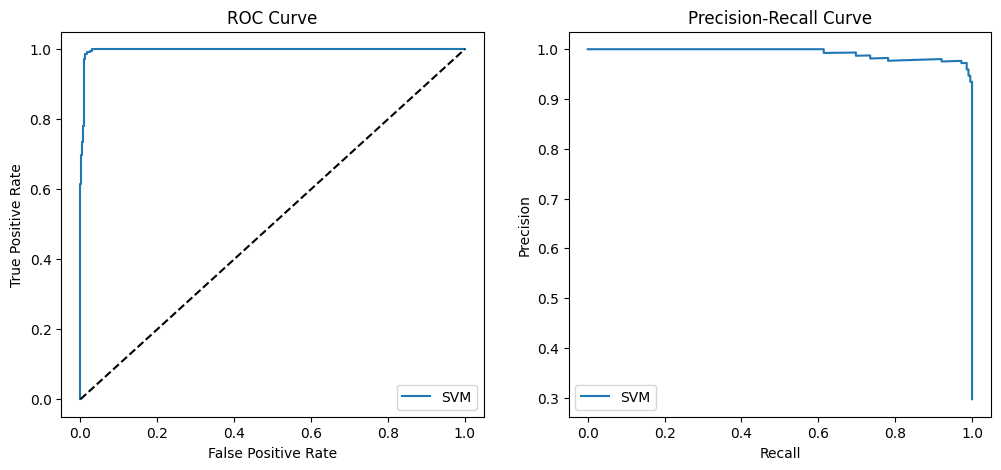

In [10]:
print("Plotting ROC and PR curves...")

def plot_roc_pr(model, X_val, y_val, name):
    probs = model.predict_proba(X_val)[:,1]

     # get values for ROC curve
    fpr, tpr, _ = roc_curve(y_val, probs)

    # getting values for Precision-Recall curve
    precision, recall, _ = precision_recall_curve(y_val, probs)

    plt.figure(figsize=(12,5))

    # ROC Curve
    plt.subplot(1,2,1)
    plt.plot(fpr, tpr, label=name)
    plt.plot([0,1],[0,1],'k--')
    plt.title('ROC Curve')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()

    # Precision-Recall Curve
    plt.subplot(1,2,2)
    plt.plot(recall, precision, label=name)
    plt.title('Precision-Recall Curve')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.legend()

    plt.show()

# plotting both models
plot_roc_pr(lr_tfidf, X_val_tfidf, y_val, "Logistic Regression")
plot_roc_pr(svm_tfidf, X_val_tfidf, y_val, "SVM")

**11. model comparison**

In [11]:
print("Building comparison table...")

models = ['NB-BoW', 'LogisticRegression-TFIDF', 'SVM-TFIDF']

# getting validation accuracy for each model
accuracies = [
    nb_bow.score(X_val_bow, y_val),
    lr_tfidf.score(X_val_tfidf, y_val),
    svm_tfidf.score(X_val_tfidf, y_val)
]

# making a table comparing all models
comparison_df = pd.DataFrame({
    'Model': models,
    'Validation Accuracy': accuracies
})

print(comparison_df)


Building comparison table...
                      Model  Validation Accuracy
0                    NB-BoW             0.970994
1  LogisticRegression-TFIDF             0.982044
2                 SVM-TFIDF             0.983425


**12. faliure case analysis**

In [12]:
print("Failure case analysis...")

import numpy as np
import random

# ensure y_val is a numpy array
if isinstance(y_val, pd.Series):
    y_val = y_val.values

# finding misclassified indices
misclassified_indices = np.where(lr_preds != y_val)[0]
print(f"Number of misclassified samples (Logistic Regression): {len(misclassified_indices)}")

# show 5 random misclassified examples
for i in random.sample(list(misclassified_indices), min(5, len(misclassified_indices))):
    print(f"\n📄 Text: {data.iloc[i]['text']}")
    print(f"✅ True Label: {y_val[i]}, ❌ Predicted Label: {lr_preds[i]}")

Failure case analysis...
Number of misclassified samples (Logistic Regression): 13

📄 Text: Subject: desk summary report
the cpr report named desk summary is currently being reviewed for an
upgrade . i have been told that this report is used during bidweek to check
positions on a particular pipe ( for a particular zone ) . if you do not need
additional data , this report could very easily be added to the report
selection in the sitara reporting application . if anyone would like to see
more detailed information on the report , please let me know . there may be a
report that is already in production that they can access .
please let me know if the format currently in cpr is sufficient as soon as
possible .
chao !
✅ True Label: 0, ❌ Predicted Label: 1

📄 Text: Subject: may wellheads
david here is the other side of the coin . these are meters that are not in
the wellhead portfolio for may but are on vances sheet . several of them
are new meters and some were just not nomed in april . vanc

**13. Save Predictions**

In [13]:
print("Saving final predictions...")

# final_preds corresponds to the correct subset of the data
final_preds = lr_tfidf.predict(X_val_tfidf)

# We can directly use `train_test_split` with `return_indices=True` to get the indices of the validation set
X_train_bow, X_val_bow, y_train, y_val, indices_train, indices_val = train_test_split(
    X_bow, y, np.arange(len(data)), test_size=0.2, random_state=42)

# now, indices_val will givess us the correctt indices for the validation set in original data
submission = pd.DataFrame({
    'Text': data.iloc[indices_val]['text'],
    'Clean_Text': data.iloc[indices_val]['clean_text'],
    'Predicted_Label': final_preds
})

# saving CSV
submission.to_csv('spam_predictions_final.csv', index=False)

print("Predictions saved successfully to spam_predictions_final.csv")


Saving final predictions...
Predictions saved successfully to spam_predictions_final.csv
